# Designing the next cohort: how many mice, and which test?

With ~half of the mtDSB mice responding, the usual "compare group means" design wastes power. This notebook
simulates future experiments from the observed per-mouse OL ISR score (log of the whole-section ISR CPM, the
prespecified readout; `results/sample_classifier/tables/sections_with_responder_calls.csv`) and compares tests.

**Generative model** (per simulated mouse): controls ~ Normal(control mean, control SD); mtDSB mice respond with
probability `p_resp` (observed 3 / 6) and are then ~ Normal(responder mean, responder SD), otherwise drawn like
controls (observed non-responders sit in the control range). Means / SDs from the 12 sections, pooling the two
cohorts after removing the slide (cohort) mean of the controls.

**Tests** (one-sided, alpha = 0.05):
* `mean`: Mann-Whitney mtDSB > control (the classic group comparison)
* `variance`: Brown-Forsythe (Levene, median) test of unequal spread
* `responder_count`: number of mtDSB mice above the control maximum + margin, vs its permutation null
* `qc_mean`: Mann-Whitney after excluding mtDSB mice that fail an induction check (assumes non-response = failed
  induction and a perfect check; the best case)

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
OUT = REPO / "results" / "design_power"; (OUT / "figures").mkdir(parents=True, exist_ok=True)
sec = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
sec["log_isr"] = np.log(sec["isr_cpm"])
# remove the cohort (slide) baseline using the controls of each cohort
base = sec[sec.group == "control"].groupby("age")["log_isr"].mean()
sec["z"] = sec["log_isr"] - sec["age"].map(base)
par = sec.groupby("group")["z"].agg(["mean", "std", "size"])
display(par.round(3))
mu_c, sd_c = par.loc["control", ["mean", "std"]]
mu_r, sd_r = par.loc["responder", ["mean", "std"]]
print(f"responder shift = {(mu_r - mu_c) / sd_c:.1f} control SDs")

,mean,std,size
group,,,
control,0.000,0.026,6
non-responder,-0.009,0.068,3
responder,0.452,0.112,3


responder shift = 17.1 control SDs


In [2]:
rng = np.random.default_rng(0)
def simulate(n, p_resp=0.5, n_sim=2000, margin=0.0):
    hits = {"mean": 0, "variance": 0, "responder_count": 0, "qc_mean": 0}
    for _ in range(n_sim):
        c = rng.normal(mu_c, sd_c, n)
        resp = rng.random(n) < p_resp
        m = np.where(resp, rng.normal(mu_r, sd_r, n), rng.normal(mu_c, sd_c, n))
        hits["mean"] += stats.mannwhitneyu(m, c, alternative="greater").pvalue < 0.05
        hits["variance"] += (stats.levene(m, c, center="median").pvalue < 0.05) and m.var() > c.var()
        # responder count: mtDSB above control max; null by permuting labels
        allv = np.r_[m, c]; obs = np.sum(m > c.max() + margin)
        null = []
        for _ in range(200):
            perm = rng.permutation(allv); null.append(np.sum(perm[:n] > perm[n:].max() + margin))
        hits["responder_count"] += np.mean(np.array(null) >= obs) < 0.05
        mq = m[resp]
        hits["qc_mean"] += len(mq) >= 2 and stats.mannwhitneyu(mq, c, alternative="greater").pvalue < 0.05
    return {k: v / n_sim for k, v in hits.items()}

grid = []
for p_resp in (0.5, 0.75):
    for n in (3, 4, 5, 6, 8, 10, 12):
        r = simulate(n, p_resp, n_sim=600)
        grid.append({"p_resp": p_resp, "n_per_group": n, **r})
power = pd.DataFrame(grid)
power.to_csv(OUT / "power_by_design.csv", index=False)
display(power.round(2))

,p_resp,n_per_group,mean,variance,responder_count,qc_mean
0,0.50,3,0.00,0.00,0.13,0.00
1,0.50,4,0.21,0.41,0.15,0.32
2,0.50,5,0.38,0.18,0.33,0.80
3,0.50,6,0.45,0.47,0.48,0.88
4,0.50,8,0.48,0.66,0.70,0.95
5,0.50,10,0.59,0.82,0.82,0.99
6,0.50,12,0.69,0.93,0.91,1.00
7,0.75,3,0.00,0.00,0.26,0.00
8,0.75,4,0.52,0.36,0.46,0.72
9,0.75,5,0.68,0.22,0.70,0.98


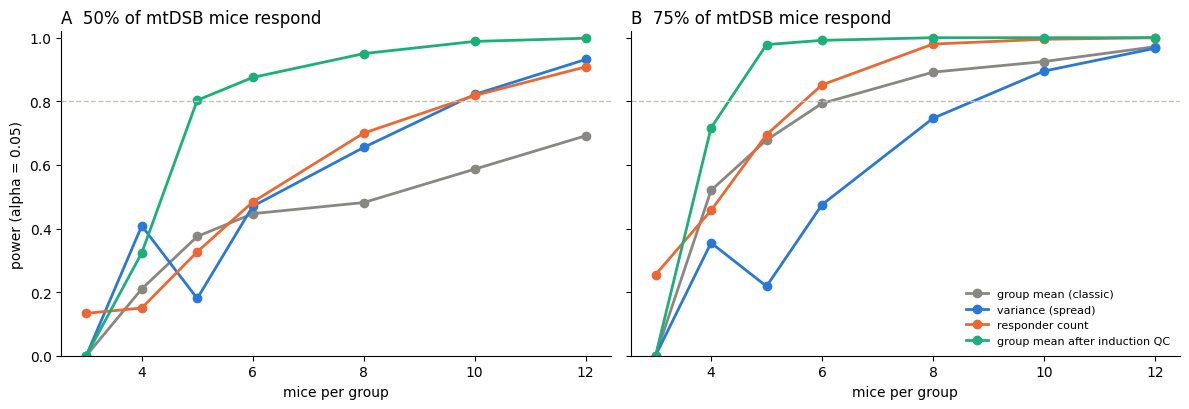

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
cols = {"mean": "#898781", "variance": "#2a78d6", "responder_count": "#eb6834", "qc_mean": "#1baf7a"}
labs = {"mean": "group mean (classic)", "variance": "variance (spread)", "responder_count": "responder count",
        "qc_mean": "group mean after induction QC"}
for ax, p in zip(axes, (0.5, 0.75)):
    d = power[power.p_resp == p]
    for k in cols:
        ax.plot(d.n_per_group, d[k], marker="o", color=cols[k], lw=2, label=labs[k])
    ax.axhline(0.8, color="#c3c2b7", ls="--", lw=1)
    ax.set_title(f"{'AB'[int(p == 0.75)]}  {int(p * 100)}% of mtDSB mice respond", loc="left")
    ax.set_xlabel("mice per group"); ax.set_ylim(0, 1.02); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("power (alpha = 0.05)"); axes[1].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "figures" / "D1_power_by_design.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT / "figures" / "D1_power_by_design.pdf", bbox_inches="tight")

**Recommendations** (see table and D1):
1. Analyse per mouse, not per group mean: test spread / count responders, and report every animal.
2. Add an induction check (mtPstI transcript or mtDNA damage) for every mouse; if non-response is failed induction,
   the classic comparison becomes well powered with few mice.
3. Keep both conditions on every slide (as now) and, if possible, both cohorts on every slide, so age and slide are
   no longer confounded.